# Дополнительная EDA: Amazon Fashion

Данный ноутбук анализирует датасет от амазона по домену модных вещей (одежда). В нем я анализирую все доступные признаки, которые затем помогут построить модель машинного обучения для рекомендаций. 

Структура приблизительно такая:
- Каталог и метаданные
- Стили оценивания пользователей
- Цена и рейтинги
- Аспекты товаров в текстах отзывов
- Поведенческие сигналы и свойства отзывов
- Магазины и концентрация отзывов

Здесь я не ищу дубликаты, не смотрю разреженность, тк этим занялись остальные члены команды. 

## 1. Загрузка данных с S3 и импорты

In [1]:
import os
import json
import ast
import ssl
import traceback
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.dataset as ds
import s3fs
import gc

FULL_DATA = True

print("AWS creds in env:", "AWS_ACCESS_KEY_ID" in os.environ and "AWS_SECRET_ACCESS_KEY" in os.environ)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


AWS creds in env: True


In [2]:
# тут ненмого неприятная подгрузка,  s3 подлагивал

S3_ENDPOINT = "https://s3.ru-7.storage.selcloud.ru"
S3_REGION = "ru-7"
S3_BUCKET = "hse-recsys-project"

_verify_env = os.environ.get("S3_VERIFY")
if _verify_env is None:
    _initial_verify = True
elif _verify_env.lower() in {"0", "false", "no"}:
    _initial_verify = False
elif _verify_env.lower() in {"1", "true", "yes"}:
    _initial_verify = True
else:
    _initial_verify = _verify_env  # path to CA bundle

def _ssl_related_error(exc):
    msg = str(exc).lower()
    names = " ".join([type(exc).__name__.lower(), getattr(type(exc), "__mro__", []) and "" ])
    markers = ["certificate_verify_failed", "cert", "ssl", "self-signed", "verify failed", "certificate"]
    return any(m in msg for m in markers)

def _make_fs(verify):
    # skip_instance_cache avoids reusing a previously broken/cached filesystem
    return s3fs.S3FileSystem(
        endpoint_url=S3_ENDPOINT,
        anon=False,
        client_kwargs={"region_name": S3_REGION, "verify": verify},
        config_kwargs={"signature_version": "s3v4"},
        skip_instance_cache=True,
    )

def _connect(verify):
    fs_local = _make_fs(verify)
    top = fs_local.ls(S3_BUCKET)
    return fs_local, top

attempts = []
try:
    fs, _top = _connect(_initial_verify)
    print("S3 connected (verify={}):".format(_initial_verify))
    print(_top)
except Exception as e1:
    attempts.append(("verify={}".format(_initial_verify), e1))
    if _initial_verify is not False and _ssl_related_error(e1):
        print("SSL verification problem detected; retrying with verify=False for trusted project endpoint...")
        try:
            fs, _top = _connect(False)
            print("S3 connected (verify=False fallback).")
            print(_top)
        except Exception as e2:
            attempts.append(("verify=False", e2))
            for label, exc in attempts:
                print(f"\n--- attempt {label} failed ---")
                print(exc)
            traceback.print_exc()
            raise
    else:
        for label, exc in attempts:
            print(f"\n--- attempt {label} failed ---")
            print(exc)
        traceback.print_exc()
        raise


SSL verification problem detected; retrying with verify=False for trusted project endpoint...
S3 connected (verify=False fallback).
['hse-recsys-project/data']


In [3]:
for part in ["reviews", "meta"]:
    folders = fs.ls(f"hse-recsys-project/data/processed/{part}")
    print(part, [f.split("/")[-1] for f in folders])

reviews ['amazon_fashion', 'grocery_and_gourmet_food']
meta ['amazon_fashion', 'grocery_and_gourmet_food']


In [4]:
CATEGORY = "amazon_fashion"
BASE = "hse-recsys-project/data/processed"
REVIEWS_PATH = f"{BASE}/reviews/{CATEGORY}"
META_PATH = f"{BASE}/meta/{CATEGORY}"

print(fs.ls(REVIEWS_PATH)[:5])

reviews_ds = ds.dataset(REVIEWS_PATH, filesystem=fs, partitioning="hive")
meta_ds = ds.dataset(META_PATH, filesystem=fs, partitioning="hive")
print("reviews schema:", reviews_ds.schema.names)
print("meta schema:", meta_ds.schema.names)


['hse-recsys-project/data/processed/reviews/amazon_fashion/_SUCCESS', 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2002', 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2003', 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2004', 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2005']
reviews schema: ['rating', 'title', 'text', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase', 'n_images', 'year']
meta schema: ['parent_asin', 'main_category', 'title', 'store', 'price', 'average_rating', 'rating_number', 'features', 'description', 'categories', 'images', 'videos', 'details', 'bought_together']


### Загрузка только необходимых полей из датасетов

In [5]:
reviews = reviews_ds.to_table(
    columns=["user_id", "parent_asin", "asin", "rating", "timestamp", "helpful_vote", "verified_purchase", "n_images", "year", "text"]
).to_pandas()

reviews["timestamp"] = pd.to_datetime(reviews["timestamp"], errors="coerce")
reviews = reviews.dropna(subset=["user_id", "parent_asin", "rating", "timestamp"])

reviews = reviews.sort_values(["helpful_vote", "n_images"], ascending=False).drop_duplicates(
    subset=["user_id", "parent_asin", "rating", "timestamp"]
)

meta = meta_ds.to_table(
    columns=["parent_asin", "main_category", "title", "store", "categories", "bought_together", "price", "average_rating", "rating_number", "features", "description"]
).to_pandas()

print("Reviews:", reviews.shape)
print("Metadata:", meta.shape)
print("Reviews years:", reviews["year"].min(), "—", reviews["year"].max())


Reviews: (2475694, 10)
Metadata: (826108, 11)
Reviews years: 2002 — 2023


In [6]:
reviews.head(3)

,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year,text
2741,AEGVVFMQXHVAGYAJXCUNPVNK53GQ,B0006URVUQ,B0006URVUQ,4,2009-05-23 00:47:20,954,False,0,2009,I bought this shirt 3 weeks ago and am just no...
30273,AEHCHHYBREOLUIFGCYYXEMNLIGHQ,B09TXZHKLG,B000GAWSDG,5,2013-04-18 22:11:19,788,False,0,2013,"During Air Force Basic Military Training, near..."
342252,AF53NGPSE326J3CRXYLLFAVCMC3Q,B00ULZAEJ6,B00ULZAEJ6,5,2016-03-28 23:43:58,714,True,0,2016,I bought these for my wife and daughter for wh...


In [7]:
meta.head(3)

,parent_asin,main_category,title,store,categories,bought_together,price,average_rating,rating_number,features,description
0,B08BHN9PK5,AMAZON FASHION,YUEDGE 5 Pairs Men's Moisture Control Cushione...,GiveGift,[],NaN,NaN,4.6,16,[],[]
1,B08R39MRDW,AMAZON FASHION,DouBCQ Women's Palazzo Lounge Wide Leg Casual ...,DouBCQ,[],NaN,NaN,4.1,7,"[Drawstring closure, Machine Wash]",[]
2,B077KJHCJ4,AMAZON FASHION,Pastel by Vivienne Honey Vanilla Girls' Trapez...,Pastel by Vivienne,[],NaN,NaN,4.3,11,"[Zipper closure, Hand Wash Only]",[]


### Аналитика уникальных значений

Важно посмотреть уникальные значения - уже с первого взгляда вижу, что categories, кажется, состоит только из скобок []. Также важно узнать уникальности других полей


In [25]:

rows = []
for col in reviews.columns:
    try:
        n = reviews[col].nunique(dropna=False)
    except Exception:
        n = np.nan
    rows.append({"dataset":"reviews", "column": col, "unique": n, "dtype": str(reviews[col].dtype)})

for col in meta.columns:
    s = meta[col]
    try:
        if s.map(lambda x: isinstance(x, (list, dict, np.ndarray))).any():
            n = s.map(lambda x: json.dumps(x, ensure_ascii=False, sort_keys=True) if isinstance(x, (dict, list)) else ("<array>" if isinstance(x, np.ndarray) else str(x))).nunique(dropna=False)
            note = "object/list/json-like"
        else:
            n = s.nunique(dropna=False)
            note = ""
    except Exception:
        n, note = np.nan, "error"
    rows.append({"dataset":"meta", "column": col, "unique": n, "dtype": str(s.dtype), "note": note})

uniq = pd.DataFrame(rows).sort_values(["dataset","column"]).reset_index(drop=True)
display(uniq)

print("Домены/диапазоны (reviews):")
for col in ["rating","verified_purchase","year","n_images","helpful_vote"]:
    if col in reviews.columns:
        vals = pd.Series(reviews[col].dropna().unique())
        if len(vals) <= 30:
            print(f"{col}: {sorted(vals.tolist())}")
        else:
            print(f"{col}: min={reviews[col].min()} max={reviews[col].max()} unique={reviews[col].nunique()}")


,dataset,column,unique,dtype,note
0,meta,average_rating,41,float64,
1,meta,bought_together,1,str,
2,meta,categories,1,object,object/list/json-like
3,meta,description,1,object,object/list/json-like
4,meta,description_length,469,int64,
5,meta,description_text,46075,str,
6,meta,features,1,object,object/list/json-like
7,meta,main_category,1,string,
8,meta,parent_asin,826108,string,
9,meta,price,5746,float64,


Домены/диапазоны (reviews):
rating: [1, 2, 3, 4, 5]
verified_purchase: [False, True]
year: [2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
n_images: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 26, 29]
helpful_vote: min=0 max=954 unique=269


Уже здесь видим пару важных поинтов - у нас нет категорий товаров (футболки/сапоги/еще что-то). Но у нас есть описания и названия товаров, которые могут скрывать категорию и предназначение товара. Начнем с описаний, тк это самый обильный по кол-ву текста домен

### Аналитика некоторых фичей


In [10]:
def clean_description(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return " ".join(str(item) for item in x)
    elif isinstance(x, str):
        return x
    else:
        return ""

meta["description_text"] = meta["description"].apply(clean_description)

meta["description_length"] = meta["description_text"].str.split().str.len()

print("Всего товаров:", len(meta))
print("Товаров с описанием:", (meta["description_length"] > 0).sum())
print("Товаров без описания:", (meta["description_length"] == 0).sum())
print("Доля товаров с описанием:", f"{(meta['description_length'] > 0).mean():.2%}")

display(meta["description_length"].describe())

Всего товаров: 826108
Товаров с описанием: 59289
Товаров без описания: 766819
Доля товаров с описанием: 7.18%


count    826108.000000
mean          6.018576
std          29.741426
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        1106.000000
Name: description_length, dtype: float64

In [28]:
item_stats = reviews.groupby("parent_asin").agg(
    mean_rating=("rating", "mean"),
    review_count=("rating", "size"),
).reset_index()

description_stats = meta[
    ["parent_asin", "description_length"]
].merge(
    item_stats[["parent_asin", "mean_rating"]],
    on="parent_asin",
    how="inner"
)

description_stats["description_bucket"] = pd.cut(
    description_stats["description_length"],
    bins=[-1, 0, 50, 150, 300, float("inf")],
    labels=["Нет описания", "1-50", "51-150", "151-300", "300+"]
)

display(
    description_stats.groupby("description_bucket", observed=True)
    ["mean_rating"].agg(["mean", "median", "count"])
)

,mean,median,count
description_bucket,,,
Нет описания,3.857225,4.250000,766587
1-50,4.123687,4.666667,25727
51-150,4.057775,4.571429,23627
151-300,3.905155,4.428571,9022
300+,4.045667,4.510000,906


У товаров хоть с каким-то описанием рейтинг выше, чем у товаров без описания

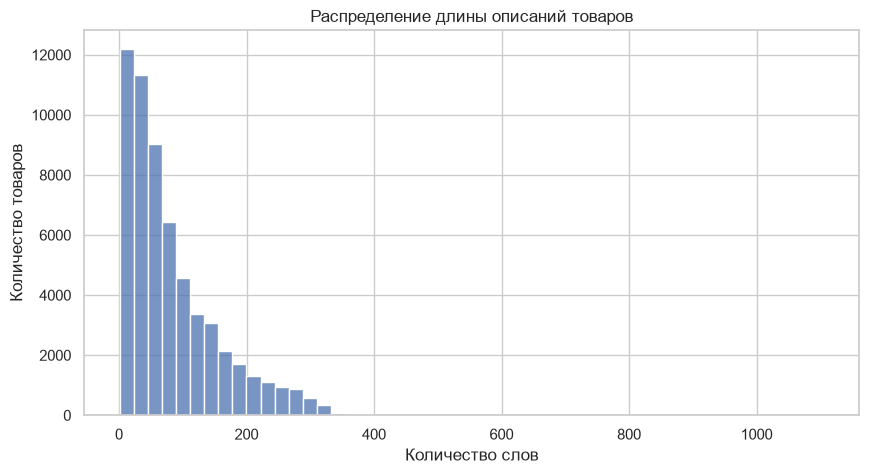

In [29]:
sns.histplot(
    meta.loc[meta["description_length"] > 0, "description_length"],
    bins=50
)

plt.title("Распределение длины описаний товаров")
plt.xlabel("Количество слов")
plt.ylabel("Количество товаров")
plt.show()

Перейдем к фичам (features)

In [30]:
def clean_features(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return [str(item) for item in x if str(item).strip()]
    elif isinstance(x, str) and x.strip():
        return [x]
    return []

meta["features_list"] = meta["features"].apply(clean_features)
meta["n_features"] = meta["features_list"].str.len()

print("Всего товаров:", len(meta))
print("С характеристиками:", (meta["n_features"] > 0).sum())
print("Без характеристик:", (meta["n_features"] == 0).sum())
print("Доля товаров с характеристиками:", f"{(meta['n_features'] > 0).mean():.2%}")
print("Среднее количество характеристик:", round(meta["n_features"].mean(), 2))

Всего товаров: 826108
С характеристиками: 463074
Без характеристик: 363034
Доля товаров с характеристиками: 56.05%
Среднее количество характеристик: 1.23


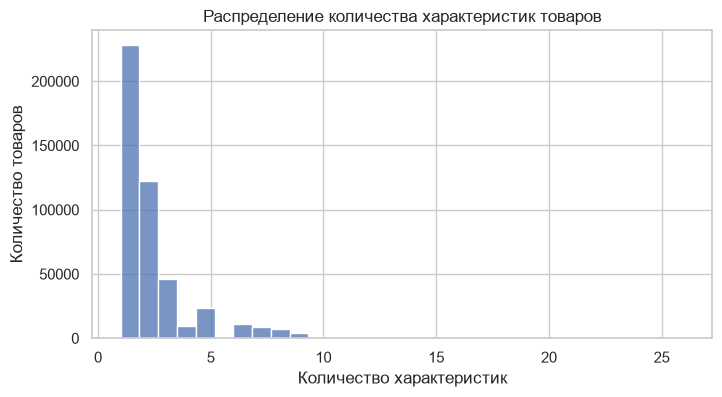

In [31]:
plt.figure(figsize=(8, 4))
sns.histplot(meta.loc[meta["n_features"] > 0, "n_features"], bins=30)
plt.title("Распределение количества характеристик товаров")
plt.xlabel("Количество характеристик")
plt.ylabel("Количество товаров")
plt.show()

In [32]:
from collections import Counter

all_features = [
    feature
    for features in meta["features_list"]
    for feature in features
]

feature_counts = Counter(all_features)

display(
    pd.DataFrame(
        feature_counts.most_common(20),
        columns=["Характеристика", "Количество"]
    )
)

,Характеристика,Количество
0,Pull On closure,103164
1,Hand Wash Only,82942
2,Machine Wash,70510
3,Button closure,32517
4,Zipper closure,31238
5,100% Cotton,25089
6,Drawstring closure,20872
7,100% Polyester,19847
8,Rubber sole,16649
9,Imported,15168


In [33]:
meta["features_group"] = pd.cut(
    meta["n_features"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=["0", "1-2", "3-5", "6-10", "10+"]
)

features_rating = meta.groupby("features_group", observed=True).agg(
    products=("parent_asin", "count"),
    mean_rating=("average_rating", "mean"),
    mean_reviews=("rating_number", "mean")
).reset_index()

display(features_rating)

,features_group,products,mean_rating,mean_reviews
0,0,363034,3.877434,10.716919
1,1-2,350729,3.896599,15.423187
2,3-5,78480,4.054782,28.129574
3,6-10,32241,4.074576,99.690301
4,10+,1624,4.155603,61.889778


Чем больше фичей у предмета, тем более он функциональный, тем выше его оценка (?)

,popularity_group,products,feature_coverage,mean_features,products_share
0,0,239,0.581590,1.251046,0.000289
1,1–5,753231,0.552188,1.182538,0.911783
2,6–10,41864,0.629825,1.523218,0.050676
3,11–25,21975,0.661024,1.801502,0.026601
4,26–50,5635,0.677906,2.210825,0.006821
5,51+,3164,0.725980,3.307838,0.003830


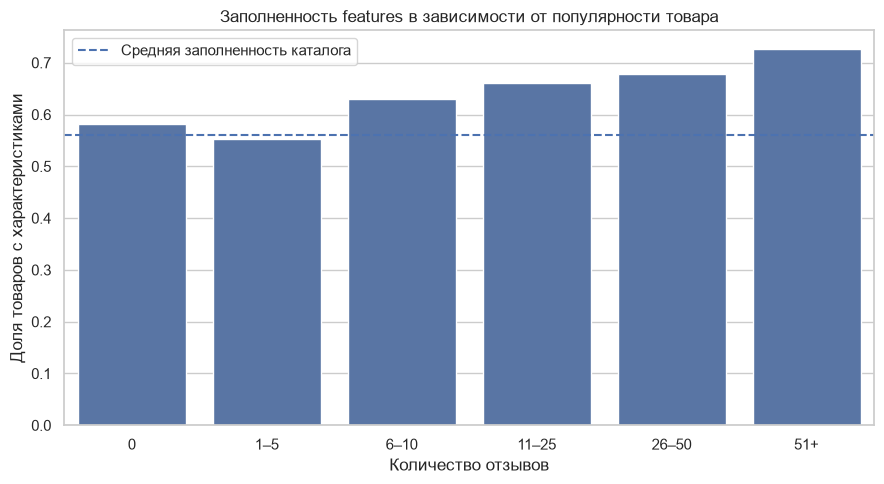

In [ ]:
review_counts = reviews.groupby("parent_asin").size().rename("review_count")

feature_popularity = meta[
    ["parent_asin", "n_features"]
].drop_duplicates("parent_asin").merge(
    review_counts,
    on="parent_asin",
    how="left"
)

feature_popularity["review_count"] = (
    feature_popularity["review_count"].fillna(0)
)

bins = [-1, 0, 5, 10, 25, 50, float("inf")]
labels = ["0", "1–5", "6–10", "11–25", "26–50", "51+"]

feature_popularity["popularity_group"] = pd.cut(
    feature_popularity["review_count"],
    bins=bins,
    labels=labels
)

feature_popularity["has_features"] = (
    feature_popularity["n_features"] > 0
)


popularity_stats = feature_popularity.groupby(
    "popularity_group", observed=False
).agg(
    products=("parent_asin", "count"),
    feature_coverage=("has_features", "mean"),
    mean_features=("n_features", "mean"),
).reset_index()

popularity_stats["products_share"] = (
    popularity_stats["products"] / len(feature_popularity)
)

display(popularity_stats)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=popularity_stats,
    x="popularity_group",
    y="feature_coverage"
)

ax.axhline(
    feature_popularity["has_features"].mean(),
    linestyle="--",
    label="Средняя заполненность каталога"
)

plt.title("Заполненность features в зависимости от популярности товара")
plt.xlabel("Количество отзывов")
plt.ylabel("Доля товаров с характеристиками")
plt.legend()
plt.tight_layout()
plt.show()

Более описанные и фнукциональные товары получают больше отзывов 

## Нормисы, критики и позитивные покупателт

Попробуем разметить клиентов с более чем 5 отзывами и посмотрим на их личный байес. Логика такая - если человек постоянно ставит плохие оценки, то высоко поставленная им оценка укажет на то, что товар реально крутой. А если нейтральный нормис поставит оценку "5", то возможно товар просто хороший, но не идеальный.

In [35]:
raters = reviews.groupby("user_id")["rating"].agg(
    review_count="count",
    mean_rating="mean",
    rating_std="std",
)

raters = raters[raters["review_count"] >= 5]

raters["rater_type"] = "Other"
raters.loc[raters["mean_rating"] >= 4.5, "rater_type"] = "Generous"
raters.loc[raters["mean_rating"] <= 3.0, "rater_type"] = "Critical"
raters.loc[raters["rating_std"] >= 1.2, "rater_type"] = "Discriminative"

# Отдельные флаги сохраняют пересечения между группами.
raters["generous"] = raters["mean_rating"] >= 4.5
raters["critical"] = raters["mean_rating"] <= 3.0
raters["discriminative"] = raters["rating_std"] >= 1.2

rater_summary = pd.DataFrame({
    "users": [
        raters["generous"].sum(),
        raters["critical"].sum(),
        raters["discriminative"].sum(),
    ]
}, index=["Generous", "Critical", "Discriminative"])

rater_summary["share"] = rater_summary["users"] / len(raters)
display(rater_summary)


,users,share
Generous,5125,0.346893
Critical,1522,0.103019
Discriminative,5815,0.393597


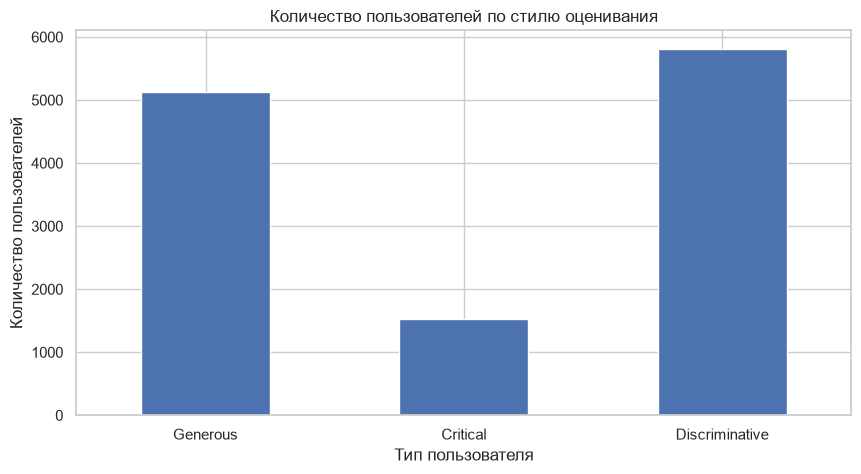

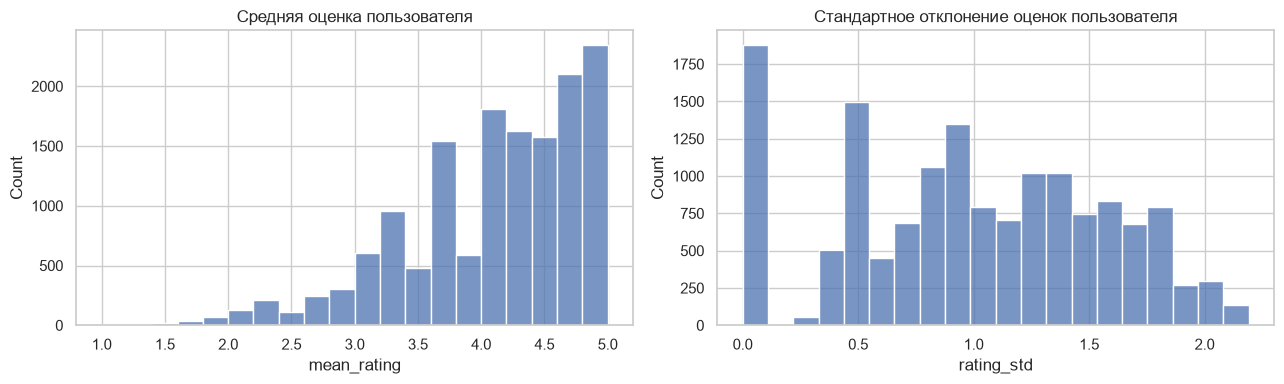

In [36]:
rater_summary["users"].plot(
    kind="bar",
    title="Количество пользователей по стилю оценивания",
    ylabel="Количество пользователей",
    xlabel="Тип пользователя",
    rot=0,
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(raters["mean_rating"], bins=20, ax=axes[0])
axes[0].set_title("Средняя оценка пользователя")
sns.histplot(raters["rating_std"].dropna(), bins=20, ax=axes[1])
axes[1].set_title("Стандартное отклонение оценок пользователя")
plt.tight_layout()
plt.show()

## Ценовые сегменты и рейтинги

Товары поделим на четыре ценовых сегмента по квантилям цены. И посмотрми на распрелоение рейтингов в них. Может, более дорогие товары гораздо качественнее дешевых?

In [37]:
prices = meta[["parent_asin", "price"]].drop_duplicates("parent_asin").copy()
prices["price"] = pd.to_numeric(prices["price"], errors="coerce")

item_ratings = reviews.groupby("parent_asin")["rating"].agg(
    review_count="count",
    mean_rating="mean",
).reset_index()

price_data = item_ratings.merge(prices, on="parent_asin", how="inner")
price_data = price_data[
    (price_data["price"] > 0)
    & (price_data["review_count"] >= 5)
].dropna(subset=["price"])

if price_data.empty:
    print("Нет товаров с валидной ценой и минимум 5 отзывами.")
else:
    price_data["price_segment"], price_bins = pd.qcut(
        price_data["price"],
        q=4,
        labels=False,
        retbins=True,
        duplicates="drop",
    )
    price_data["price_segment"] = price_data["price_segment"].map(
        lambda x: f"Q{int(x) + 1}"
    )

    display(
        price_data.groupby("price_segment", observed=True)
        .agg(
            products=("parent_asin", "nunique"),
            min_price=("price", "min"),
            median_price=("price", "median"),
            max_price=("price", "max"),
            mean_rating=("mean_rating", "mean"),
        )
    )

,products,min_price,median_price,max_price,mean_rating
price_segment,,,,,
Q1,2795,0.01,7.99,10.00,4.019451
Q2,2967,10.04,13.89,16.99,4.138397
Q3,2607,17.00,21.99,29.90,4.181045
Q4,2779,29.92,45.00,2473.00,4.248751


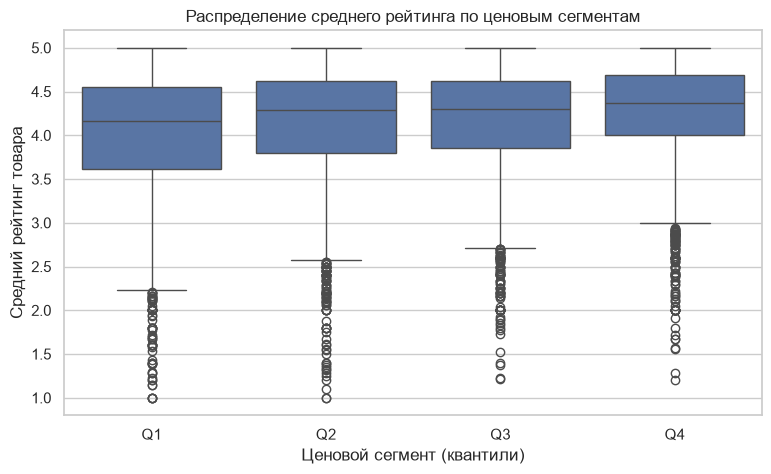

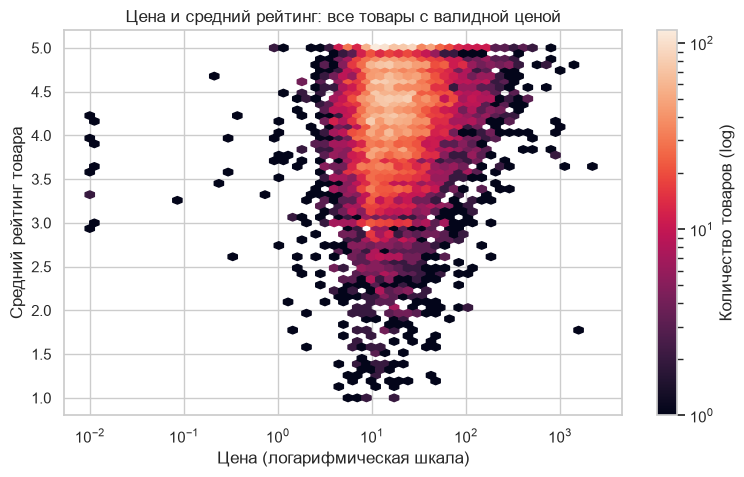

In [38]:
# зададим порядок по названию
price_data["price_segment"] = pd.Categorical(
    price_data["price_segment"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

if not price_data.empty:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=price_data, x="price_segment", y="mean_rating")
    plt.title("Распределение среднего рейтинга по ценовым сегментам")
    plt.xlabel("Ценовой сегмент (квантили)")
    plt.ylabel("Средний рейтинг товара")
    plt.show()

    # В график передаются все товары из price_data.
    # Hexbin агрегирует отображение, но не делает выборку строк.
    plt.figure(figsize=(9, 5))
    plt.hexbin(
        price_data["price"],
        price_data["mean_rating"],
        gridsize=55,
        mincnt=1,
        xscale="log",
        bins="log",
    )
    plt.colorbar(label="Количество товаров (log)")
    plt.title("Цена и средний рейтинг: все товары с валидной ценой")
    plt.xlabel("Цена (логарифмическая шкала)")
    plt.ylabel("Средний рейтинг товара")
    plt.show()

У более дорогих товаров рейтинг чуть лучше. Но не сильно

##  Тексты отзывов - какие характеристики важны пользователям

Тут просто решила вытянуть ключевые реплики из отзывов самым простым способом (без nlp методов особо). Посмотрим, какие слова чаще всего встречаются в отзывах у людей, потом может интерпретировать это как фичу тональности

In [39]:
import warnings
warnings.filterwarnings("ignore")

TEXT_BATCH = globals().get('TEXT_BATCH', 50_000)
aspect_patterns = {
    'Fit and size': r'\b(fit|fits|fitting|size|sizing|small|large|tight|loose|narrow|wide|length|short|long)\b',
    'Comfort': r'\b(comfort|comfortable|uncomfortable|soft|cozy|itchy|scratchy|breathable|lightweight)\b',
    'Quality and material': r'\b(quality|material|fabric|stitching|seam|durable|cheaply|flimsy|thin|thick|cotton|leather)\b',
    'Appearance and style': r'\b(look|looks|style|stylish|cute|beautiful|pretty|color|colour|design|fashion)\b',
    'Value and price': r'\b(price|cost|expensive|cheap|value|worth|overpriced|affordable)\b',
    'Delivery and packaging': r'\b(shipping|delivery|arrived|late|fast|damaged|package|packaging|box)\b',
    'Accuracy vs description/photo': r'\b(described|description|pictured|picture|photo|expected|advertised|misleading|different)\b',
    'Return/exchange': r'\b(return|returned|exchange|refund|replacement)\b',
}

aspect_totals = {
    aspect: {"reviews": 0, "rating_sum": 0.0, "negative": 0, "positive": 0}
    for aspect in aspect_patterns
}
total_text_reviews = 0
scanner = reviews_ds.scanner(columns=["rating", "text"], batch_size=TEXT_BATCH)

for batch in scanner.to_batches():
    batch_df = batch.to_pandas(self_destruct=True).dropna(subset=["text"])
    if batch_df.empty:
        continue
    total_text_reviews += len(batch_df)
    ratings = batch_df["rating"]
    for aspect, pattern in aspect_patterns.items():
        mask = batch_df["text"].str.contains(pattern, case=False, na=False, regex=True)
        matched_ratings = ratings[mask]
        aspect_totals[aspect]["reviews"] += int(mask.sum())
        aspect_totals[aspect]["rating_sum"] += float(matched_ratings.sum())
        aspect_totals[aspect]["negative"] += int((matched_ratings <= 2).sum())
        aspect_totals[aspect]["positive"] += int((matched_ratings >= 4).sum())
    del batch_df, ratings

aspect_results = []
for aspect, stats in aspect_totals.items():
    count = stats["reviews"]
    aspect_results.append({
        "aspect": aspect,
        "reviews": count,
        "share": count / total_text_reviews if total_text_reviews else 0,
        "mean_rating": stats["rating_sum"] / count if count else np.nan,
        "negative_share": stats["negative"] / count if count else np.nan,
        "positive_share": stats["positive"] / count if count else np.nan,
    })

aspect_stats = pd.DataFrame(aspect_results).sort_values("reviews", ascending=False)
print("Всего обработано отзывов с непустым текстом:", total_text_reviews)
display(aspect_stats)

Всего обработано отзывов с непустым текстом: 2500939


,aspect,reviews,share,mean_rating,negative_share,positive_share
0,Fit and size,919554,0.367683,3.835795,0.203855,0.665927
3,Appearance and style,769872,0.307833,4.056472,0.152640,0.730447
2,Quality and material,554448,0.221696,3.757369,0.234561,0.645007
1,Comfort,313333,0.125286,4.409701,0.081999,0.844533
6,Accuracy vs description/photo,288420,0.115325,3.694463,0.242584,0.628635
4,Value and price,276424,0.110528,3.773410,0.238633,0.663781
5,Delivery and packaging,123077,0.049212,3.800564,0.241832,0.669800
7,Return/exchange,94288,0.037701,2.551767,0.543060,0.289772


### Полезность отзывов

Посмотрим, какие отзывы обычно считают полезными - зависит ли это от длины? А бывают ли у нас боты, которые спамят отзывами со скоростью света?

Всего отзывов: 2500939
Доля отзывов с helpful vote: 19.78%


,Длина отзыва,Количество отзывов,Доля с helpful vote,Среднее helpful vote,Средний рейтинг
0,0-19 слов,1397879,0.120298,0.228241,4.102641
1,20-79,954587,0.265179,0.746547,3.793085
2,80-199,133344,0.482324,2.291277,3.826486
3,200+,15129,0.604072,5.153348,4.053936


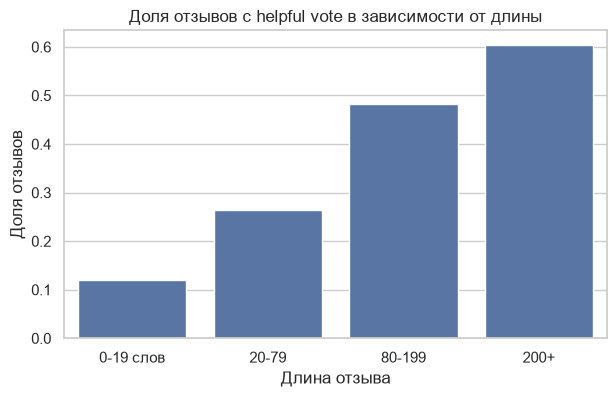

In [40]:
len_labels = ["0-19 слов", "20-79", "80-199", "200+"]

agg = {
    label: {
        "reviews": 0,
        "helpful": 0,
        "helpful_sum": 0,
        "rating_sum": 0
    }
    for label in len_labels
}

total = 0
helpful_total = 0

for batch in reviews_ds.scanner(
    columns=["rating", "helpful_vote", "text"],
    batch_size=50_000
).to_batches():

    df = batch.to_pandas()

    word_count = df["text"].fillna("").str.split().str.len()

    df["len_bucket"] = pd.cut(
        word_count,
        bins=[-1, 19, 79, 199, float("inf")],
        labels=len_labels
    )

    df["helpful_vote"] = df["helpful_vote"].fillna(0)

    total += len(df)
    helpful_total += (df["helpful_vote"] > 0).sum()

    for label, group in df.groupby("len_bucket", observed=True):
        stats = agg[label]

        stats["reviews"] += len(group)
        stats["helpful"] += (group["helpful_vote"] > 0).sum()
        stats["helpful_sum"] += group["helpful_vote"].sum()
        stats["rating_sum"] += group["rating"].sum()


rows = []

for label in len_labels:
    stats = agg[label]
    n = stats["reviews"]

    rows.append({
        "Длина отзыва": label,
        "Количество отзывов": n,
        "Доля с helpful vote": stats["helpful"] / n if n else 0,
        "Среднее helpful vote": stats["helpful_sum"] / n if n else 0,
        "Средний рейтинг": stats["rating_sum"] / n if n else 0
    })

summary = pd.DataFrame(rows)

print("Всего отзывов:", total)
print("Доля отзывов с helpful vote:", f"{helpful_total / total:.2%}")

display(summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=summary, x="Длина отзыва", y="Доля с helpful vote")
plt.title("Доля отзывов с helpful vote в зависимости от длины")
plt.xlabel("Длина отзыва")
plt.ylabel("Доля отзывов")
plt.show()

Чем длиннее отзыв, тем он чаще отмечается полезным. Потом можно будет работать с этим как с nlp базой

###  Темп активности пользователей - интервалы между отзывами (боты)

Интервал между отзывами помогает отличать эпизодических покупателей/писателей от регулярных. И тут же попробуем выявить ботов, которые за 1 день написали кучу отзывов 


Пользователей с >=2 отзывами: 282166
Медианный интервал (дни): 160.95072292824074
Доля интервалов <= 1 дня: 0.18808098063625048
Доля интервалов <= 30 дней: 0.3024506819565474


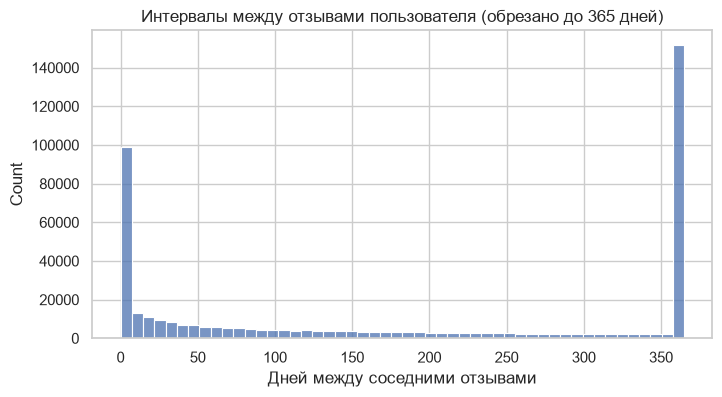

In [41]:
u = reviews.sort_values(["user_id", "timestamp"])[["user_id","timestamp","parent_asin"]].copy()
u["prev_ts"] = u.groupby("user_id")["timestamp"].shift(1)
u["gap_days"] = (u["timestamp"] - u["prev_ts"]).dt.total_seconds() / 86400
gaps = u.dropna(subset=["gap_days"])
print("Пользователей с >=2 отзывами:", u.groupby("user_id").size().gt(1).sum())
print("Медианный интервал (дни):", gaps["gap_days"].median())
print("Доля интервалов <= 1 дня:", (gaps["gap_days"] <= 1).mean())
print("Доля интервалов <= 30 дней:", (gaps["gap_days"] <= 30).mean())
plt.figure(figsize=(8,4))
sns.histplot(gaps["gap_days"].clip(upper=365), bins=50)
plt.title("Интервалы между отзывами пользователя (обрезано до 365 дней)")
plt.xlabel("Дней между соседними отзывами")
plt.show()


In [42]:
reviews["date"] = reviews["timestamp"].dt.date

daily_activity = (
    reviews.groupby(["user_id", "date"])
    .size()
    .reset_index(name="reviews_per_day")
)

display(daily_activity.sort_values(
    "reviews_per_day",
    ascending=False
).head(20))

,user_id,date,reviews_per_day
339362,AEM5PO3PITEPDNNATSGM2PD6C62Q,2018-06-29,18
1030514,AFR2XB7TRMQJCRB6INYP2W73EH5A,2021-06-08,16
305453,AEKEF7PBXCP345X2UPV3IJY6QMNQ,2017-01-06,13
2004685,AHF7II6UR3KZ7456G4LVM5K4JVQQ,2019-01-04,13
1022576,AFQNKOJVCTSPUXQIHHKIZHUC4U2Q,2014-12-04,13
1582198,AGON3GV6Q37EUUSTQUWEAZ35D5JA,2017-04-15,12
1148317,AFXF3EGQTQDXMRLDWFU7UBFQZB7Q,2020-11-29,11
443634,AERPMJNZRD76NEI6NJBPRXKKEPMQ,2022-05-16,11
351856,AEMT4Q3OEWSJWLOWNPGL6JLI7IIA,2015-10-22,10
765735,AFCXBV3VMX2TP5V4RBPM744BBZAA,2017-10-10,10


Кажется, это боты. Посмотрим, похожи ли их отзывы в течение дня. Если там 100% попадание в одинаковость, то это бот

In [43]:
reviews[reviews['user_id']=='AEM5PO3PITEPDNNATSGM2PD6C62Q']

,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year,text,date
1014431,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01MUDAJ7M,B01MUDAJ7M,5,2018-06-29 02:50:32.293,0,True,0,2018,Very pretty.,2018-06-29
1014432,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01N24YB55,B01N24YB55,5,2018-06-29 02:49:11.908,0,True,0,2018,Very cute.,2018-06-29
1014433,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01N13KGF1,B01N13KGF1,5,2018-06-29 02:47:48.764,0,True,0,2018,Very cute.,2018-06-29
1014434,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01FLLDD7E,B01FLLDD7E,5,2018-06-29 02:32:14.003,0,True,0,2018,Very pretty.,2018-06-29
1014435,AEM5PO3PITEPDNNATSGM2PD6C62Q,B00X146JT8,B00X146JT8,5,2018-06-29 02:30:50.116,0,True,0,2018,Very pretty.,2018-06-29
1014436,AEM5PO3PITEPDNNATSGM2PD6C62Q,B00X1466G4,B00X1466G4,5,2018-06-29 02:30:20.854,0,True,0,2018,Very pretty.,2018-06-29
1014437,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01M247J0I,B01M247J0I,5,2018-06-29 02:28:01.764,0,True,0,2018,Cute.,2018-06-29
1014438,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01FD9PGVU,B01FD9PGVU,5,2018-06-29 02:26:59.271,0,True,0,2018,Beautiful.,2018-06-29
1014439,AEM5PO3PITEPDNNATSGM2PD6C62Q,B00X146PC4,B00X146PC4,5,2018-06-29 02:26:48.271,0,True,0,2018,Awesome.,2018-06-29
1014440,AEM5PO3PITEPDNNATSGM2PD6C62Q,B01FD9PB42,B01FD9PB42,5,2018-06-29 02:26:35.058,0,True,0,2018,"Intricate design, very nice.",2018-06-29


In [44]:
reviews[(reviews['user_id']=='AFR2XB7TRMQJCRB6INYP2W73EH5A')&(reviews["timestamp"].dt.normalize() == pd.Timestamp("2021-06-08"))]

,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year,text,date
2136439,AFR2XB7TRMQJCRB6INYP2W73EH5A,B083Q357C8,B083Q357C8,4,2021-06-08 21:33:47.137,0,False,0,2021,"good quality, plenty of storage space",2021-06-08
2136440,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08GKFJF9Z,B08GKFJF9Z,5,2021-06-08 21:19:07.901,0,False,0,2021,"super cute, fit as expected",2021-06-08
2136441,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08NG3WDXZ,B08NG3WDXZ,5,2021-06-08 21:07:02.136,0,False,0,2021,"great quality, thin material, fit as expected",2021-06-08
2136442,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08N6BRWCZ,B08N6BRWCZ,5,2021-06-08 21:06:34.792,0,False,0,2021,"great quality, fit as expected",2021-06-08
2136443,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08QCRXSZ8,B08QCRXSZ8,5,2021-06-08 21:01:06.547,0,False,0,2021,"good quality, accurate, and durable",2021-06-08
2136444,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08SHYB3Y3,B08SHYB3Y3,5,2021-06-08 20:34:03.277,0,False,0,2021,"great quality, cute, comfy, and fit as expected",2021-06-08
2136445,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08L77Z6MV,B08L77Z6MV,5,2021-06-08 20:04:00.197,0,False,0,2021,fit as expected,2021-06-08
2136446,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08SPY9MD8,B08SPY9MD8,5,2021-06-08 20:01:43.696,0,False,0,2021,"super cute, comfy, and fit as expected",2021-06-08
2136447,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08NCG23KV,B08NCG23KV,5,2021-06-08 19:54:30.140,0,False,0,2021,"great quality, fit as expected, and extra comf...",2021-06-08
2136448,AFR2XB7TRMQJCRB6INYP2W73EH5A,B08SGMLRMJ,B08SGMLRMJ,5,2021-06-08 19:54:06.210,0,False,0,2021,"cute, comfy, and fit as expected",2021-06-08


In [45]:
reviews[(reviews['user_id']=='AEKEF7PBXCP345X2UPV3IJY6QMNQ')&(reviews["timestamp"].dt.normalize() == pd.Timestamp("2017-01-06"))]

,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year,text,date
772617,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B016JYIU34,B016JYIU34,5,2017-01-06 09:44:56,14,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772611,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00Z974DTI,B00Z974DTI,5,2017-01-06 10:30:05,3,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772613,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00X146DJE,B00X146DJE,5,2017-01-06 10:18:03,1,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772614,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00X146EMU,B00X146EMU,5,2017-01-06 10:17:21,1,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772623,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B016JYISMC,B016JYISMC,5,2017-01-06 09:37:50,1,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772612,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00X146JJI,B00X146JJI,5,2017-01-06 10:19:28,0,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772615,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00X146SX0,B00X146SX0,5,2017-01-06 10:17:05,0,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772616,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B01F76JAB6,B01F76JAB6,5,2017-01-06 10:16:33,0,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772618,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B00X146PC4,B00X146PC4,5,2017-01-06 09:42:21,0,True,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06
772619,AEKEF7PBXCP345X2UPV3IJY6QMNQ,B01FLLDD7E,B01FLLDD7E,5,2017-01-06 09:41:45,0,False,0,2017,"Beautiful, exactly as described, couldn't be h...",2017-01-06


Очень похоже на бота. Здесь же заметно, что он пишет некоторые отзывы с разницей в 20 секунд. Попробуем нарисовать распределение разниц между соседними комментами в минутах. Будем считать ботами тех, кто слишком быстро пишет отзывы. А потом с нлп-методами можно будет находить реальных ботов (оч похожая семантика отзывов) и удалять их из анализа

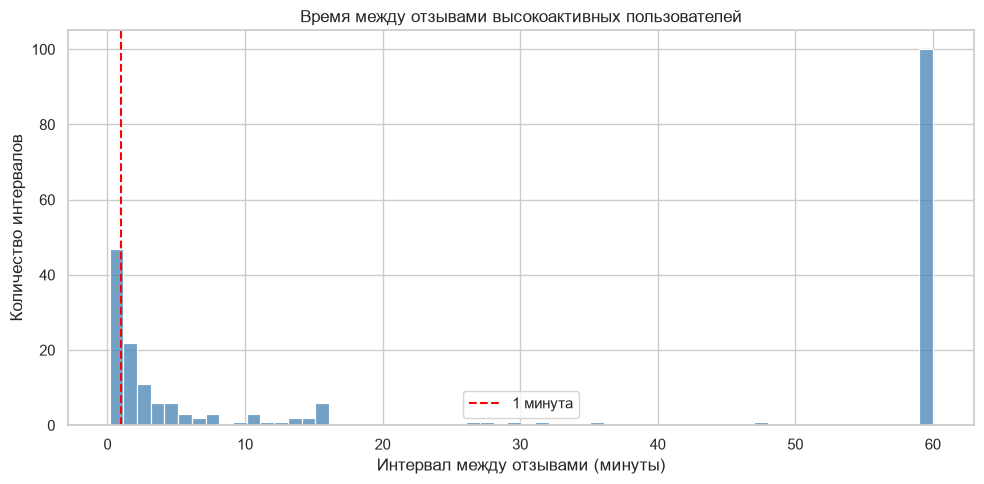

Медианный интервал: 15.42 мин.
Интервал до 1 минуты: 18.47%
Интервал до 5 минут: 41.44%


In [ ]:
daily_counts = reviews.groupby(
    [reviews["user_id"], reviews["timestamp"].dt.date]
).size()

active_users = daily_counts[daily_counts > 10].index.get_level_values(0).unique()

bot_candidates = reviews[reviews["user_id"].isin(active_users)].copy()
bot_candidates = bot_candidates.sort_values(["user_id", "timestamp"])

bot_candidates["time_diff"] = (
    bot_candidates.groupby("user_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)
intervals = bot_candidates["time_diff"].dropna()

plt.figure(figsize=(10, 5))
sns.histplot(intervals.clip(upper=60), bins=60, color="steelblue")

plt.axvline(1, color="red", linestyle="--", label="1 минута")
plt.xlabel("Интервал между отзывами (минуты)")
plt.ylabel("Количество интервалов")
plt.title("Время между отзывами высокоактивных пользователей")
plt.legend()
plt.tight_layout()
plt.show()

print("Медианный интервал:", round(intervals.median(), 2), "мин.")
print("Интервал до 1 минуты:", f"{(intervals <= 1).mean():.2%}")
print("Интервал до 5 минут:", f"{(intervals <= 5).mean():.2%}")

### Verified purchase, фото в отзыве и нишевость

Проверяем, отличаются ли оценки по verified purchase и наличию фото - отдельно считаем долю нишевых товаров (мало отзывов), там гораздо важнее контент/метаданные - посмотрел фоточку и понял что хочешь купить


In [47]:
vp = reviews.groupby("verified_purchase")["rating"].agg(["size","mean"]).rename(columns={"size":"reviews"})
img = reviews.assign(has_img=reviews["n_images"].fillna(0) > 0).groupby("has_img")["rating"].agg(["size","mean"]).rename(columns={"size":"reviews"})
print("Verified purchase:"); display(vp)
print("Есть фото в отзыве:"); display(img)

item_n = reviews.groupby("parent_asin").size().rename("n_reviews").reset_index()
bins = [0,1,2,5,10,50,10**9]
labels = ["1","2","3-5","6-10","11-50","51+"]
item_n["bucket"] = pd.cut(item_n["n_reviews"], bins=bins, labels=labels)
niche = item_n["bucket"].value_counts().sort_index().rename("items").to_frame()
niche["share"] = niche["items"]/niche["items"].sum()
display(niche)
print(f"Нишевые товары (<=2 отзывов): {(item_n['n_reviews']<=2).mean():.2%}")
print(f"Товары с <=5 отзывов: {(item_n['n_reviews']<=5).mean():.2%}")


Verified purchase:


,reviews,mean
verified_purchase,,
False,161622,3.958094
True,2314072,3.970628


Есть фото в отзыве:


,reviews,mean
has_img,,
False,2317176,3.971483
True,158518,3.945344


,items,share
bucket,,
1,493632,0.597712
2,142220,0.172206
3-5,117379,0.142128
6-10,41864,0.050691
11-50,27610,0.033431
51+,3164,0.003831


Нишевые товары (<=2 отзывов): 76.99%
Товары с <=5 отзывов: 91.20%


### Бренды и магазины 

Смотрим концентрацию отзывов, различия в рейтингах, а еще посмотрим, есть ли истинно плохие магазины, которых заваливают плохими отзывами. Посмотрим на долю людей, которые покупают товары только в 1 магазине. И в обратную сторону - магазины только с 1 товаром


,store,items,reviews,users,mean_item_rating
51506,NELEUS,539,15294,15273,3.529289
61653,Romwe,4150,10856,10856,3.645145
13898,Casio,284,9763,9697,4.408075
52911,Nike,5152,8872,8835,4.388806
12349,CHUVORA,1332,8559,8559,4.081211
27430,GRACE KARIN,3832,8458,8458,3.945656
76117,Verdusa,3723,8429,8429,3.697143
3987,Allegra K,2013,8390,8390,3.997096
19285,Disney,2849,8143,8142,4.335407
25566,Floerns,3438,7377,7377,3.503261


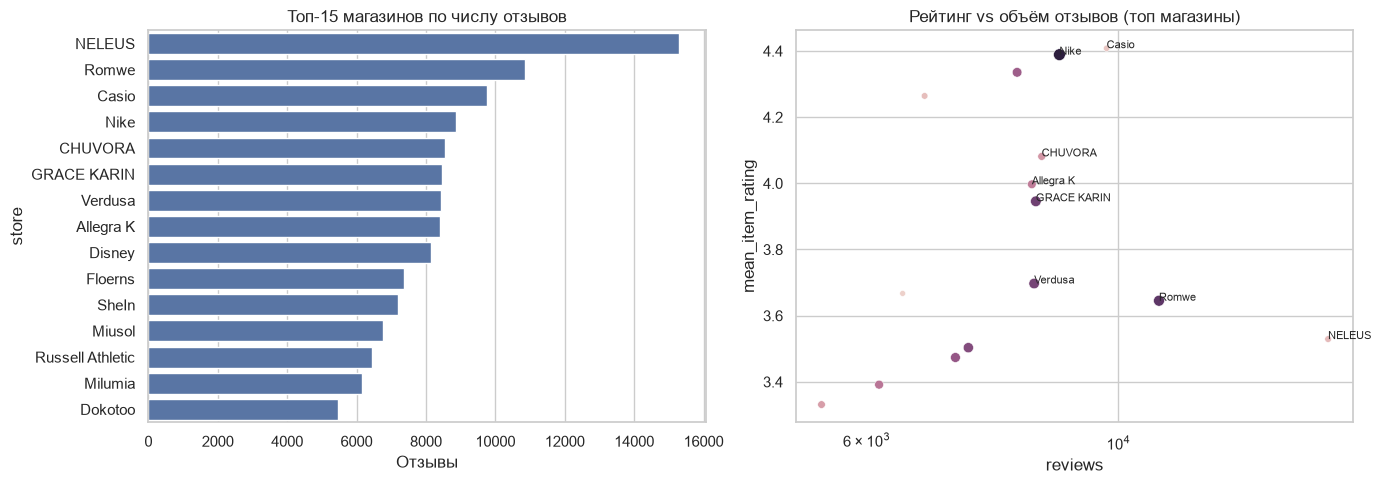

Доля multi-item пользователей, писавших отзывы только об одном магазине: 3.38%


In [48]:
store_meta = meta[["parent_asin", "store"]].drop_duplicates("parent_asin").copy()
store_meta["store"] = store_meta["store"].fillna("Unknown").astype(str).str.strip()
store_meta.loc[store_meta["store"] == "", "store"] = "Unknown"

item_stats_store = reviews.groupby("parent_asin", observed=True).agg(
    n_reviews=("rating", "size"),
    mean_rating=("rating", "mean"),
    n_users=("user_id", "nunique"),
).reset_index()
item_store = item_stats_store.merge(store_meta, on="parent_asin", how="left")
item_store["store"] = item_store["store"].astype(str).fillna("Unknown")

store_summary = item_store.groupby("store", observed=True).agg(
    items=("parent_asin", "nunique"),
    reviews=("n_reviews", "sum"),
    users=("n_users", "sum"),
    mean_item_rating=("mean_rating", "mean"),
).reset_index()
store_summary = store_summary[store_summary["store"] != "Unknown"]
top_stores = store_summary.nlargest(15, "reviews")
display(top_stores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_stores, y="store", x="reviews", ax=axes[0])
axes[0].set_title("Топ-15 магазинов по числу отзывов")
axes[0].set_xlabel("Отзывы")
sns.scatterplot(data=top_stores, x="reviews", y="mean_item_rating", size="items", hue="items", ax=axes[1], legend=False)
for _, r in top_stores.head(8).iterrows():
    axes[1].annotate(str(r["store"])[:18], (r["reviews"], r["mean_item_rating"]), fontsize=8)
axes[1].set_title("Рейтинг vs объём отзывов (топ магазины)")
axes[1].set_xscale("log")
plt.tight_layout(); plt.show()

ui_store = reviews[["user_id", "parent_asin"]].drop_duplicates().merge(store_meta[["parent_asin","store"]], on="parent_asin", how="left")
ui_store["store"] = ui_store["store"].astype(str).fillna("Unknown")
multi_u = ui_store.groupby("user_id")["parent_asin"].nunique()
ui_multi = ui_store[ui_store["user_id"].isin(multi_u[multi_u >= 2].index)]
same_store_share = ui_multi.groupby("user_id")["store"].nunique().eq(1).mean() if not ui_multi.empty else np.nan
print(f"Доля multi-item пользователей, писавших отзывы только об одном магазине: {same_store_share:.2%}" if pd.notna(same_store_share) else "n/a")


In [49]:
review_store = reviews.merge(store_meta, on="parent_asin", how="left")

negative = review_store.groupby("store").agg(
    reviews=("rating", "size"),
    negative_share=("rating", lambda x: (x <= 2).mean())
).query("reviews >= 100").reset_index()

display(negative.nlargest(15, "negative_share"))

,store,reviews,negative_share
524,Borje,117,0.829060
716,Choarica,158,0.822785
3299,Soo slick,106,0.811321
4055,amousa,151,0.781457
3666,VEROP,161,0.732919
3860,WooCo,102,0.715686
1459,Goldenchen,129,0.713178
3200,Seabaras,207,0.681159
327,BERYUAN,110,0.672727
204,Andees-USA STOCK Women Leggings,106,0.650943


In [50]:
store_items = item_store.groupby("store")["parent_asin"].nunique()

print("Количество магазинов с одним товаром:", (store_items == 1).sum())

Количество магазинов с одним товаром: 38765


## Краткие выводы 

Что потенциально может быть полезно для построения рексиса:

- Фичи товара, число характеристик, текстоые представления
- Поведение юзера (какой у него паттерн оценивания товаров?)
- Число отзывов на товар, средний рейтинг, разброс оценок, доля подтвержденных ревью и наличие фоток
- Длины отзывов, содержания, пометка "полезный отзыв" 


Что заметила:
- Есть боты
- Нет категорий товаров (можно попробовать вытянуть из названия или описания отзывов (длинных) )
- Было бы круто иметь на руках клики или просмотры товаров (или папку "избранное")
